# GTF / 01: USD/JPY gotobi days and the Tokyo fix — replication and independent test

Protocol: [`001_claude_gtf01_preregistration.md`](../../discussions/Gotobi_Tokyo_Fix/001_claude_gtf01_preregistration.md). Gates are fixed there.

**Rule (video):** on a gotobi day sell USD/JPY at 09:55 JST (00:55 UTC) at the bid, stop at fill + 12 pips (ask), buy back at 10:30 JST (01:30 UTC) at the ask.
**Paper (Ito & Yamada 2017):** the mid rises into the 09:55 fix on gotobi days.

| Window | Dates | Role |
|---|---|---|
| INDEPENDENT | 2010–2015 | binding, not used by the video |
| REPLICATION | 2016–2025 | the video's sample (2026 excluded) |
| Sealed | 2026 → | refused in code |

| Gate | Condition (α = 0.025, one-sided) |
|---|---|
| G1 statistical | gotobi P&L after spread: HAC p ≤ α and block-bootstrap lower bound > 0 (blocks 10, 20) |
| G2 calendar | gotobi − control: Welch p ≤ α, and above 10,000 random calendars (same days per month): p ≤ α |
| G3 economic | net at c = $35/M/side: bootstrap lower bound > 0 (10, 20), and mean net at c = $70 > 0 |

`GTF_SYNTHETIC=1` runs offline on synthetic ticks with an injected effect (outputs to `01_synthetic/`).

In [1]:
import json, os, sys, tempfile
import datetime as dt
from dataclasses import replace, asdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("GTF_SYNTHETIC") == "1"
if SYNTHETIC:                                   # never touch the real market-data folder in a smoke run
    os.environ["EQUITY_TRADING_DIR"] = tempfile.mkdtemp(prefix="gtf01_")
    os.environ.pop("DUKASCOPY_DIR", None)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import gotobi as G

cfg = G.GTFConfig()
WINDOWS = dict(G.WINDOWS)
if SYNTHETIC:
    WINDOWS = {"INDEPENDENT": (dt.date(2014, 1, 1), dt.date(2014, 12, 31)),
               "REPLICATION": (dt.date(2016, 1, 1), dt.date(2016, 12, 31))}
    cfg = replace(cfg, n_boot=2_000, n_random_calendars=1_000)
START = min(w[0] for w in WINDOWS.values())
END = max(w[1] for w in WINDOWS.values())
OUT = Path.cwd() / ("01_synthetic" if SYNTHETIC else "01")
OUT.mkdir(exist_ok=True)
BASE = G.grid_key(cfg.entry_min, cfg.exit_min, cfg.stop_pips)
JST = lambda m: f"{9 + m // 60:02d}:{m % 60:02d}"
pd.set_option("display.width", 200, "display.max_columns", 40)
print(f"gotobi {G.GOTOBI_VERSION} | synthetic={SYNTHETIC} | {START} -> {END} | base rule {BASE} | out {OUT}")

gotobi 0.1.0 | synthetic=False | 2010-01-01 -> 2025-12-31 | base rule pnl_e55_x90_s12 | out D:\Projects\equity_trading\notebooks\Gotobi_Tokyo_Fix\01


## 0. Synthetic inputs (smoke run only)

Random-walk ticks 00:00–02:00 UTC for 2014–2016 with a +2 pip drift into 00:55 and −3 pips to 01:30 on gotobi days. The verdict must come out positive here; on the real data it can come out anything.

In [2]:
if SYNTHETIC:
    G.write_synthetic(Path(os.environ["EQUITY_TRADING_DIR"]) / "Dukascopy", START, END)

## 1. Data folder and calendar

The folder is the downloader's output with hours 00–01 UTC (`hours_all` or `hours_00-01-02-22-23`). Set `DUKASCOPY_DIR` if the downloader's `--out` is not `<EQUITY_TRADING_DIR>/Dukascopy`.

In [3]:
root = G.dukascopy_root()
print("ticks:", root)
cal = G.day_table(START, END)
cal["year"] = pd.to_datetime(cal["date"]).dt.year
cal_year = cal.groupby("year").agg(weekdays=("date", "size"), bank_days=("jp_bank_day", "sum"),
                                   gotobi=("gotobi", "sum"), gotobi_month_end_conv=("gotobi_m", "sum"),
                                   jp_holidays=("day_type", lambda s: (s == "jp_holiday").sum()))
display(cal_year)
print("gotobi days per year: mean", round(cal_year["gotobi"].mean(), 1), "(video: ~72 trades/year)")
display(cal[cal["gotobi"]].head(12)[["date", "weekday", "gotobi_month_end"]])

ticks: D:\MarketData\Dukascopy\USDJPY\hours_00-01-02-22-23


,weekdays,bank_days,gotobi,gotobi_month_end_conv,jp_holidays
year,,,,,
2010,261,245,70,74,16
2011,260,245,71,77,15
2012,261,248,71,77,13
2013,261,245,71,76,16
2014,261,244,70,75,17
2015,261,244,71,75,17
2016,261,245,71,76,16
2017,260,247,71,78,13
2018,261,245,71,77,16


gotobi days per year: mean 70.6 (video: ~72 trades/year)


,date,weekday,gotobi_month_end
2,2010-01-05,1,False
5,2010-01-08,4,False
10,2010-01-15,4,False
13,2010-01-20,2,False
16,2010-01-25,0,False
20,2010-01-29,4,True
25,2010-02-05,4,False
28,2010-02-10,2,False
31,2010-02-15,0,False
35,2010-02-19,4,False


## 2. Per-day outcomes

One pass over every weekday file: the full trade grid (entry 09:54/55/56, exit 10:15/10:30/10:45, stop 8/12/20/none), the pre-fix long, the mid path 09:00–10:45 JST, and the spread at the fix. Cached under `<EQUITY_TRADING_DIR>/EquityTrading/Gotobi/`.

In [4]:
days = G.build_day_outcomes(START, END, cfg, root=root, n_jobs=4)
days["window"] = None
for w, (a, b) in WINDOWS.items():
    days.loc[(days["date"] >= a) & (days["date"] <= b), "window"] = w
days["month_key"] = pd.to_datetime(days["date"]).dt.year * 12 + pd.to_datetime(days["date"]).dt.month
days["net_gate"] = G.net_pips(days[BASE], days["mid_fix"], cfg.commission_usd_per_m)
days["net_2x"] = G.net_pips(days[BASE], days["mid_fix"], 2 * cfg.commission_usd_per_m)
days["pre_mid_pips"] = (days["mid_055"] - days["mid_000"]) / G.PIP
days["post_mid_pips"] = (days["mid_090"] - days["mid_055"]) / G.PIP
print(len(days), "weekdays;", int(days["has_file"].sum()), "with a file")

4174 weekdays; 4174 with a file


## 3. Coverage and spread at the fix

A bank day without a file, or without a fill within 30 s of 09:55 / 10:30, is not traded. Large gaps in a year make that year's statistics unreliable.

In [5]:
cov = (days.assign(valid=days[BASE].notna())
          .groupby(["year", "day_type"]).agg(days=("date", "size"), files=("has_file", "sum"), valid=("valid", "sum"))
          .unstack("day_type"))
display(cov)
missing = days[days["jp_bank_day"] & ~days["has_file"].fillna(False)]
print(f"bank days without a file: {len(missing)}")
display(missing[["date", "day_type"]].head(20))
print("base-trade exit reasons on gotobi days:")
display(days[days["day_type"] == "gotobi"].groupby("window")["base_reason"].value_counts().unstack(fill_value=0))
spr = days.groupby(["year", "day_type"])["spread_fix_pips"].median().unstack()
display(spr.round(2))
cov.to_csv(OUT / "01_coverage.csv"); spr.to_csv(OUT / "01_spread_at_fix.csv")

days                     files                     valid                  
day_type control gotobi jp_holiday control gotobi jp_holiday control gotobi jp_holiday
year                                                                                  
2010         175     70         16     175     70         16     171     68         15
2011         174     71         15     174     71         15     173     68         13
2012         177     71         13     177     71         13     172     71         11
2013         174     71         16     174     71         16     173     70         15
2014         174     70         17     174     70         17     173     69         15
2015         173     71         17     173     71         17     173     71         16
2016         174     71         16     174     71         16     174     71         15
2017         176     71         13     176     71         13     176     71         12
2018         174     71         16     174     71         16     174     71         15
2019         171     70         20     171     70         20     171     70         19
2020         173     70         19     173     70         19     173     70         18
2021         175     70         16     175     70         16     175     70         15
2022         173     71         16     173     71         16     173     71         16
2023         175     71         14     175     71         14     175     70         13
2024         174     71         17     174     71         17     174     71         16
2025         173     70         18     173     70         18     173     69         17

bank days without a file: 0


,date,day_type


base-trade exit reasons on gotobi days:


base_reason,no_exit,stop,time
window,,,
INDEPENDENT,6,55,362
REPLICATION,2,129,575


day_type,control,gotobi,jp_holiday
year,,,
2010,1.0,0.80,1.00
2011,1.0,1.00,1.20
2012,0.7,0.80,0.80
2013,0.6,0.60,0.60
2014,0.4,0.35,0.40
2015,0.3,0.40,0.50
2016,0.3,0.40,0.60
2017,0.3,0.30,0.40
2018,0.3,0.30,0.30


## 4. Average mid path 09:00–10:45 JST

Mid minus the 09:55 mid, in pips. The paper predicts the gotobi line rises into 09:55; the video's trade needs it to fall afterwards. Japanese holidays (no fix) are a natural placebo.

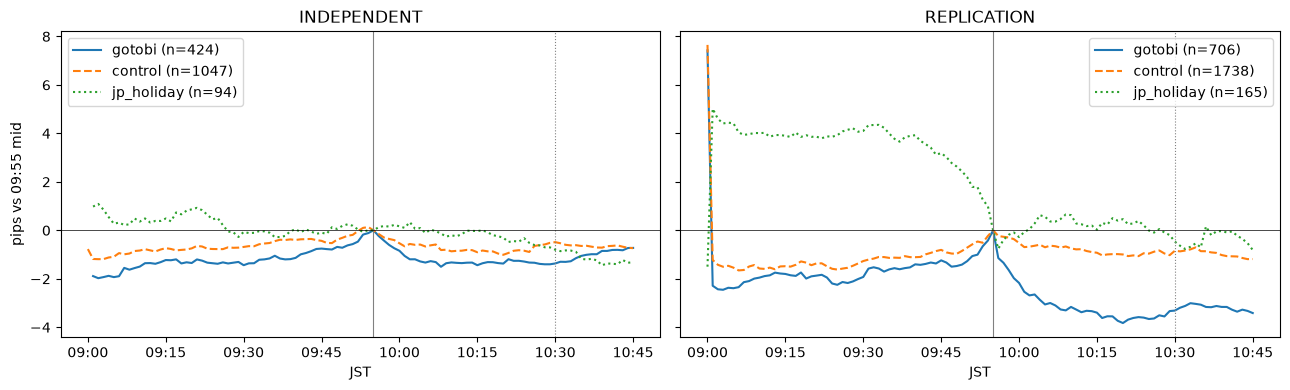

In [6]:
mins = list(cfg.path_minutes)
cols = [f"mid_{m:03d}" for m in mins]
fig, axes = plt.subplots(1, len(WINDOWS), figsize=(13, 4), sharey=True)
paths = {}
for ax, w in zip(np.atleast_1d(axes), WINDOWS):
    d = days[days["window"] == w]
    rel = d[cols].sub(d["mid_fix"], axis=0) / G.PIP
    for t, style in [("gotobi", "-"), ("control", "--"), ("jp_holiday", ":")]:
        m = rel[d["day_type"] == t].mean()
        paths[(w, t)] = m.to_numpy()
        ax.plot(mins, m.to_numpy(), style, label=f"{t} (n={int((d['day_type'] == t).sum())})")
    ax.axvline(55, color="grey", lw=0.8); ax.axvline(90, color="grey", lw=0.8, ls=":")
    ax.axhline(0, color="black", lw=0.5)
    ax.set_xticks(range(0, 106, 15)); ax.set_xticklabels([JST(m) for m in range(0, 106, 15)])
    ax.set_title(w); ax.set_xlabel("JST"); ax.legend()
np.atleast_1d(axes)[0].set_ylabel("pips vs 09:55 mid")
plt.tight_layout(); plt.savefig(OUT / "01_mid_path.png", dpi=120); plt.show()
pd.DataFrame({f"{w}|{t}": v for (w, t), v in paths.items()}, index=[JST(m) for m in mins]).to_csv(OUT / "01_mid_path.csv")

## 5. H1 — pre-fix move (paper)

Mid at 09:55 minus mid at 09:00 JST, gotobi vs control, Welch one-sided. Reported separately; it does not enter the trading verdict. The tradable long (buy ask 09:00, sell bid 09:55) is shown for reference.

In [7]:
h1 = {}
for w in WINDOWS:
    d = days[days["window"] == w]
    g, c = d[d["day_type"] == "gotobi"], d[d["day_type"] == "control"]
    r = G.welch_diff(g["pre_mid_pips"], c["pre_mid_pips"])
    r.update(gotobi_mean=float(g["pre_mid_pips"].mean()), control_mean=float(c["pre_mid_pips"].mean()),
             holiday_mean=float(d.loc[d["day_type"] == "jp_holiday", "pre_mid_pips"].mean()),
             gotobi_long_after_spread=float(g["prefix_long_pips"].mean()),
             verdict="H1_REPLICATES" if r["diff"] > 0 and r["p_one_sided"] <= cfg.alpha else "H1_NOT_REPLICATED")
    h1[w] = r
h1_tab = pd.DataFrame(h1).T
display(h1_tab)
h1_tab.to_csv(OUT / "01_h1_prefix.csv")

D:\Projects\equity_trading\src\equity_trading\gotobi.py:332: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  r = ttest_ind(a, b, equal_var=False, alternative="greater")
D:\Projects\equity_trading\src\equity_trading\gotobi.py:333: RuntimeWarning: Mean of empty slice
  return {"diff": float(a.mean() - b.mean()), "t": float(r.statistic), "p_one_sided": float(r.pvalue),
D:\Anaconda\envs\equity-trading\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,diff,t,p_one_sided,n_a,n_b,gotobi_mean,control_mean,holiday_mean,gotobi_long_after_spread,verdict
INDEPENDENT,NaN,NaN,NaN,0,2,NaN,0.775,NaN,0.843026,H1_NOT_REPLICATED
REPLICATION,0.225,0.010922,0.496332,2,4,-7.425,-7.65,1.5,1.794468,H1_NOT_REPLICATED


## 6. H2 — the video rule: gates G1–G3

Trades in date order. Random calendars draw, in every month, as many bank days (with a valid trade) as that month has gotobi days.

,trades,mean_after_spread,hac_t,hac_p,win_rate,boot_lower,control_mean,diff,welch_p,random_cal_max,random_cal_p,commission_pips_mean,mean_net_c35,boot_net_lower,mean_net_c70
INDEPENDENT,417,0.771223,1.770108,0.038355,0.534772,"[0.001181, 0.026115]",0.347343,0.42388,0.197683,1.86283,0.212579,NaN,0.102844,"[-0.668829, -0.650288]",-0.565536
REPLICATION,704,2.640341,5.53558,0.0,0.59375,"[1.651112, 1.61076]",0.292693,2.347648,0.000003,2.267187,0.0001,0.861659,1.779198,"[0.795349, 0.758568]",0.918056


,window,G1_statistical,G2_calendar,G3_economic
INDEPENDENT,INDEPENDENT,False,False,False
REPLICATION,REPLICATION,True,True,True


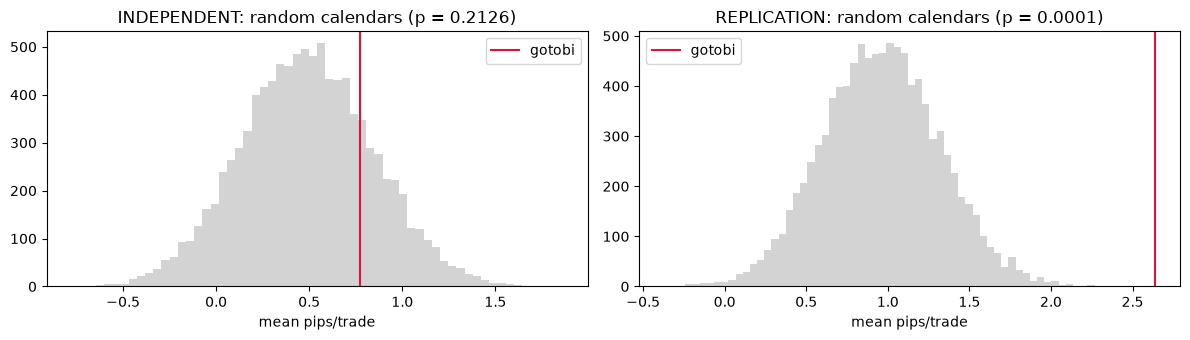

In [8]:
def evaluate(w):
    d = days[days["window"] == w].sort_values("date")
    g, c = d[d["day_type"] == "gotobi"], d[d["day_type"] == "control"]
    x = g[BASE].dropna().to_numpy()
    hac = G.hac_mean(x, cfg.hac_lags)
    boot = [G.block_bootstrap_lower(x, b, cfg.n_boot, cfg.alpha, cfg.seed) for b in cfg.blocks]
    diff = G.welch_diff(x, c[BASE])
    bank = d[d["jp_bank_day"]]
    rand = G.random_calendar_means(bank[BASE].to_numpy(), bank["month_key"].to_numpy(), bank["gotobi"].to_numpy(),
                                   cfg.n_random_calendars, cfg.seed)
    rank = G.placebo_rank(x.mean(), rand)
    net = g["net_gate"].dropna().to_numpy()
    boot_net = [G.block_bootstrap_lower(net, b, cfg.n_boot, cfg.alpha, cfg.seed) for b in cfg.blocks]
    net2 = float(g["net_2x"].mean())
    gt = G.gates(w, hac, boot, diff, rank, boot_net, net2, cfg.alpha)
    stats = {"trades": int(len(x)), "mean_after_spread": hac["mean"], "hac_t": hac["t"], "hac_p": hac["p_one_sided"],
             "win_rate": float((x > 0).mean()), "boot_lower": [b["lower"] for b in boot],
             "control_mean": float(c[BASE].mean()), "diff": diff["diff"], "welch_p": diff["p_one_sided"],
             "random_cal_max": rank["placebo_max"], "random_cal_p": rank["p_upper"],
             "commission_pips_mean": float(G.commission_pips(g["mid_fix"], cfg.commission_usd_per_m).mean()),
             "mean_net_c35": float(net.mean()), "boot_net_lower": [b["lower"] for b in boot_net], "mean_net_c70": net2}
    return gt, stats, rand

gate_res, stat_res, rand_res = {}, {}, {}
for w in WINDOWS:
    gate_res[w], stat_res[w], rand_res[w] = evaluate(w)
display(pd.DataFrame(stat_res).T)
display(pd.DataFrame(gate_res).T)
pd.DataFrame(stat_res).T.to_csv(OUT / "01_h2_stats.csv"); pd.DataFrame(gate_res).T.to_csv(OUT / "01_h2_gates.csv")

fig, axes = plt.subplots(1, len(WINDOWS), figsize=(12, 3.5))
for ax, w in zip(np.atleast_1d(axes), WINDOWS):
    ax.hist(rand_res[w], bins=60, color="lightgrey")
    ax.axvline(stat_res[w]["mean_after_spread"], color="crimson", label="gotobi")
    ax.set_title(f"{w}: random calendars (p = {stat_res[w]['random_cal_p']:.4f})"); ax.set_xlabel("mean pips/trade"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "01_random_calendars.png", dpi=120); plt.show()

## 7. By year

The video reports every year 2016–2025 positive after spread, 2021 weakest (+0.5) and 2022 / 2025 above +4.

,trades,mean_after_spread,win_rate,mean_net_c35,stops,control_mean
year,,,,,,
2010,68,1.66,0.56,1.05,11,0.23
2011,68,2.11,0.62,1.55,5,0.53
2012,71,-0.45,0.46,-1.01,5,0.14
2013,70,1.41,0.51,0.73,13,1.52
2014,69,-0.17,0.51,-0.91,9,-0.56
2015,71,0.14,0.55,-0.71,12,0.21
2016,71,2.52,0.55,1.76,22,-0.53
2017,71,2.46,0.61,1.67,7,0.19
2018,71,0.93,0.56,0.16,11,-0.36


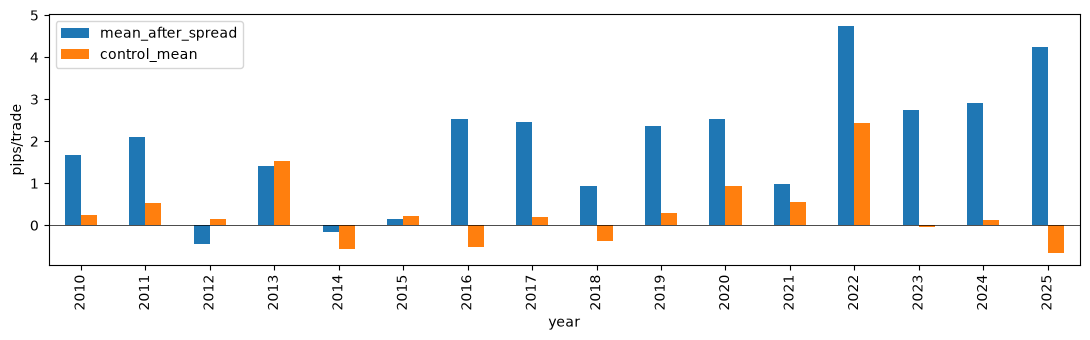

In [9]:
g_all = days[days["day_type"] == "gotobi"]
by_year = g_all.groupby("year").agg(trades=(BASE, "count"), mean_after_spread=(BASE, "mean"),
                                    win_rate=(BASE, lambda s: (s.dropna() > 0).mean()),
                                    mean_net_c35=("net_gate", "mean"), stops=("base_reason", lambda s: (s == "stop").sum()))
by_year["control_mean"] = days[days["day_type"] == "control"].groupby("year")[BASE].mean()
display(by_year.round(2))
by_year.to_csv(OUT / "01_by_year.csv")
ax = by_year[["mean_after_spread", "control_mean"]].plot.bar(figsize=(11, 3.5)); ax.axhline(0, color="black", lw=0.5)
ax.set_ylabel("pips/trade"); plt.tight_layout(); plt.savefig(OUT / "01_by_year.png", dpi=120); plt.show()

## 8. Robustness (reported, not gated)

None of these rescue a failed gate. A cell that beats the base rule is a hypothesis for a new pre-registration, testable only on the 2026 holdout.

In [10]:
rows = []
for w in WINDOWS:
    d = days[days["window"] == w]
    bank = d[d["jp_bank_day"]]
    def add(name, mask, col=BASE):
        s = bank.loc[mask, col].dropna()
        rows.append({"window": w, "variant": name, "n": len(s), "mean": s.mean(), "win_rate": (s > 0).mean()})
    add("base: gotobi", bank["gotobi"])
    add("control", ~bank["gotobi"])
    for k in (-3, -2, -1, 1, 2, 3):
        add(f"shift {k:+d} bank days", G.shifted_calendar(bank, k).to_numpy())
    add("month-end convention (gotobi_m)", bank["gotobi_m"])
    add("gotobi: month-end (30th / last)", bank["gotobi"] & bank["gotobi_month_end"])
    add("gotobi: 5th-25th", bank["gotobi"] & ~bank["gotobi_month_end"])
    add("gotobi excl. intervention days", bank["gotobi"] & ~bank["intervention"])
    for wd, name in enumerate(["Mon", "Tue", "Wed", "Thu", "Fri"]):
        add(f"gotobi on {name}", bank["gotobi"] & (bank["weekday"] == wd))
    hol = d[d["day_type"] == "jp_holiday"][BASE].dropna()
    rows.append({"window": w, "variant": "JP holidays (no fix)", "n": len(hol), "mean": hol.mean(), "win_rate": (hol > 0).mean()})
rob = pd.DataFrame(rows)
display(rob.pivot(index="variant", columns="window", values=["n", "mean"]).round(2))
rob.to_csv(OUT / "01_robustness.csv", index=False)

n                    mean            
window                          INDEPENDENT REPLICATION INDEPENDENT REPLICATION
variant                                                                        
JP holidays (no fix)                   85.0       156.0        0.29        0.61
base: gotobi                          417.0       704.0        0.77        2.64
control                              1035.0      1738.0        0.35        0.29
gotobi excl. intervention days        414.0       702.0        0.75        2.65
gotobi on Fri                         182.0       299.0        1.53        2.55
gotobi on Mon                          52.0        94.0       -0.53        2.42
gotobi on Thu                          64.0       105.0        0.44        2.16
gotobi on Tue                          59.0       101.0       -0.09        2.20
gotobi on Wed                          60.0       105.0        0.78        3.98
gotobi: 5th-25th                      352.0       594.0        0.98        2.70
gotobi: month-end (30th / last)        65.0       110.0       -0.36        2.34
month-end convention (gotobi_m)       447.0       759.0        0.69        2.68
shift +1 bank days                    422.0       705.0        0.42        0.43
shift +2 bank days                    417.0       705.0        0.20        0.62
shift +3 bank days                    414.0       704.0        0.53        1.18
shift -1 bank days                    416.0       706.0        0.86        0.39
shift -2 bank days                    422.0       705.0       -0.12        0.73
shift -3 bank days                    418.0       704.0        0.50        1.35

In [11]:
grid = []
for w in WINDOWS:
    d = days[days["window"] == w]
    for e in cfg.grid_entry:
        for x in cfg.grid_exit:
            for s in cfg.grid_stop:
                k = G.grid_key(e, x, s)
                g, c = d.loc[d["day_type"] == "gotobi", k], d.loc[d["day_type"] == "control", k]
                grid.append({"window": w, "entry": JST(e), "exit": JST(x), "stop": s if s else "none",
                             "gotobi_mean": g.mean(), "control_mean": c.mean(), "diff": g.mean() - c.mean(), "n": int(g.count())})
grid = pd.DataFrame(grid)
display(grid.pivot_table(index=["entry", "exit", "stop"], columns="window", values="gotobi_mean").round(2))
grid.to_csv(OUT / "01_grid.csv", index=False)

window            INDEPENDENT  REPLICATION
entry exit  stop                          
09:54 10:15 8.0          0.77         1.77
            12.0         0.71         1.89
            20.0         0.61         2.07
            none         0.64         2.46
      10:30 8.0          0.67         1.94
            12.0         0.64         1.92
            20.0         0.54         2.13
            none         0.62         2.40
      10:45 8.0          0.60         2.04
            12.0         0.50         1.84
            20.0         0.26         2.18
            none        -0.04         2.50
09:55 10:15 8.0          0.96         2.48
            12.0         0.93         2.54
            20.0         0.87         2.81
            none         0.83         2.96
      10:30 8.0          0.83         2.46
            12.0         0.77         2.64
            20.0         0.84         2.83
            none         0.79         2.90
      10:45 8.0          0.78         2.59
            12.0         0.67         2.64
            20.0         0.56         2.93
            none         0.15         3.00
09:56 10:15 8.0          0.78         1.23
            12.0         0.65         1.39
            20.0         0.56         1.53
            none         0.51         1.74
      10:30 8.0          0.48         1.18
            12.0         0.45         1.42
            20.0         0.50         1.56
            none         0.47         1.68
      10:45 8.0          0.44         1.38
            12.0         0.30         1.61
            20.0         0.24         1.68
            none        -0.18         1.77

## 9. Costs, slippage and sizing

Break-even commission c* (USD per $1M per side) solves mean gross = mean commission. Equity: 0.5% risk per trade with the 12-pip stop, net at c = 35, the windows in sequence.

window,INDEPENDENT,REPLICATION
mean_after_spread,0.77,2.64
break_even_c_usd_per_m,40.39,107.31
net c=0 slip=0.0,0.77,2.64
net c=0 slip=0.2,0.37,2.24
net c=0 slip=0.5,-0.23,1.64
net c=18 slip=0.0,0.43,2.20
net c=18 slip=0.2,0.03,1.80
net c=18 slip=0.5,-0.57,1.20
net c=35 slip=0.0,0.10,1.78
net c=35 slip=0.2,-0.30,1.38


equity x1.696 over 16.0 years -> 3.36%/yr; max drawdown -7.30%


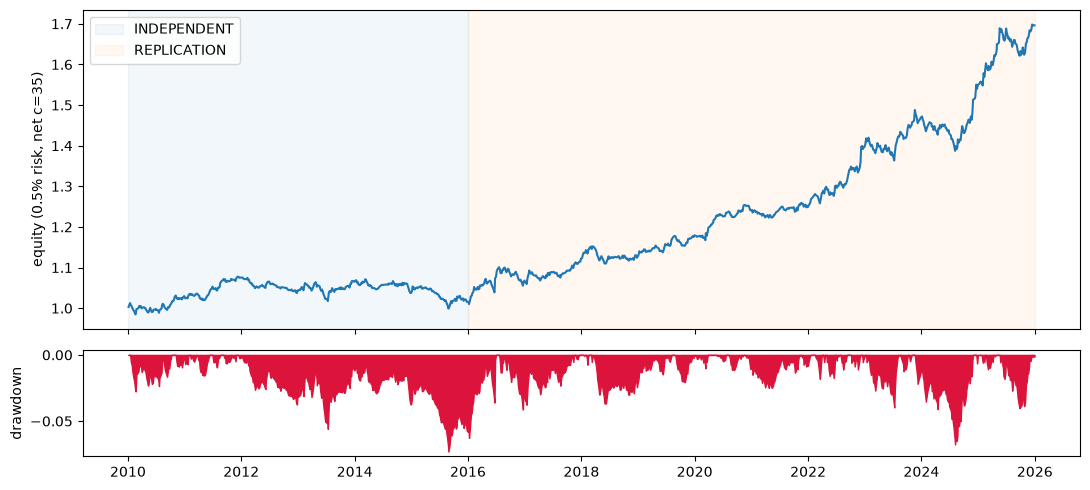

In [12]:
cost_rows = []
for w in WINDOWS:
    g = days[(days["window"] == w) & (days["day_type"] == "gotobi")].dropna(subset=[BASE])
    per_c = (2 * g["mid_fix"] / 10_000).mean()          # pips per $1/M/side of commission
    row = {"window": w, "mean_after_spread": g[BASE].mean(), "break_even_c_usd_per_m": g[BASE].mean() / per_c}
    for c in (0, 18, 35, 70):
        for slip in (0.0, 0.2, 0.5):
            row[f"net c={c} slip={slip}"] = G.net_pips(g[BASE], g["mid_fix"], c, slip).mean()
    cost_rows.append(row)
costs = pd.DataFrame(cost_rows).set_index("window").T
display(costs.round(2))
costs.to_csv(OUT / "01_costs.csv")

g = days[(days["day_type"] == "gotobi") & days["window"].notna()].dropna(subset=[BASE]).sort_values("date").set_index("date")
eq = G.equity_curve(g["net_gate"], risk=0.005, stop_pips=cfg.stop_pips or 12.0)
eq["window"] = g["window"]
yrs = (pd.Timestamp(g.index[-1]) - pd.Timestamp(g.index[0])).days / 365.25
print(f"equity x{eq['equity'].iloc[-1]:.3f} over {yrs:.1f} years -> {eq['equity'].iloc[-1] ** (1 / yrs) - 1:.2%}/yr; "
      f"max drawdown {eq['drawdown'].min():.2%}")
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax[0].plot(pd.to_datetime(eq.index), eq["equity"]); ax[0].set_ylabel("equity (0.5% risk, net c=35)")
for w, (a, b) in WINDOWS.items():
    ax[0].axvspan(pd.Timestamp(a), pd.Timestamp(b), alpha=0.06, color="C0" if w == "INDEPENDENT" else "C1", label=w)
ax[0].legend(); ax[1].fill_between(pd.to_datetime(eq.index), eq["drawdown"], 0, color="crimson"); ax[1].set_ylabel("drawdown")
plt.tight_layout(); plt.savefig(OUT / "01_equity.png", dpi=120); plt.show()
eq.to_csv(OUT / "01_equity.csv")

## 10. Verdict

In [13]:
v = G.verdict(gate_res)
summary = {"study": "GTF01", "gotobi_version": G.GOTOBI_VERSION, "synthetic": SYNTHETIC, "data_root": str(root),
           "windows": {w: [str(a), str(b)] for w, (a, b) in WINDOWS.items()},
           "config": {k: (list(v_) if isinstance(v_, tuple) else v_) for k, v_ in asdict(cfg).items() if k != "path_minutes"},
           "h1": {w: h1[w]["verdict"] for w in WINDOWS}, "gates": gate_res, "stats": stat_res, **v}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps({k: summary[k] for k in ("h1", "gates")} | v, indent=2))

{
  "h1": {
    "INDEPENDENT": "H1_NOT_REPLICATED",
    "REPLICATION": "H1_NOT_REPLICATED"
  },
  "gates": {
    "INDEPENDENT": {
      "window": "INDEPENDENT",
      "G1_statistical": false,
      "G2_calendar": false,
      "G3_economic": false
    },
    "REPLICATION": {
      "window": "REPLICATION",
      "G1_statistical": true,
      "G2_calendar": true,
      "G3_economic": true
    }
  },
  "replication_2016_2025": "REPLICATES",
  "independent_2010_2015": "NOT_CONFIRMED",
  "economic_both_windows": false,
  "verdict": "NO_EDGE"
}
